In [22]:
!pip install lifelines -q

import numpy as np # linear algebra
import matplotlib.pyplot as plt
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/WiDSWorldWide_GlobalDathon26/sample_submission.csv
/kaggle/input/competitions/WiDSWorldWide_GlobalDathon26/train.csv
/kaggle/input/competitions/WiDSWorldWide_GlobalDathon26/metaData.csv
/kaggle/input/competitions/WiDSWorldWide_GlobalDathon26/test.csv


In [23]:
train = pd.read_csv('/kaggle/input/competitions/WiDSWorldWide_GlobalDathon26/train.csv') 
print(train.shape) 
print(train['event'].value_counts())

(221, 37)
event
0    152
1     69
Name: count, dtype: int64


In [24]:
corr = train.drop(columns=['event_id', 'time_to_hit_hours']).corrwith(train['event']).abs().sort_values(ascending=False)
print("event와의 상관관계")
print(corr.head(10))

corr_time = train.drop(columns=['event_id', 'event']).corrwith(train['time_to_hit_hours']).abs().sort_values(ascending=False)
print("time_to_hit_hours와의 상관관계")
print(corr_time.head(10))

event와의 상관관계
event                           1.000000
dist_min_ci_0_5h                0.481379
low_temporal_resolution_0_5h    0.379117
num_perimeters_0_5h             0.370501
dt_first_last_0_5h              0.352954
alignment_abs                   0.349115
spread_bearing_cos              0.323189
log1p_growth                    0.292688
spread_bearing_deg              0.281012
log_area_ratio_0_5h             0.229327
dtype: float64
time_to_hit_hours와의 상관관계
time_to_hit_hours               1.000000
low_temporal_resolution_0_5h    0.442236
dt_first_last_0_5h              0.434699
num_perimeters_0_5h             0.392040
spread_bearing_cos              0.370451
alignment_abs                   0.366923
spread_bearing_deg              0.335598
dist_min_ci_0_5h                0.324876
log1p_growth                    0.317451
dist_fit_r2_0_5h                0.284143
dtype: float64


low_temporal_resolution_0_5h:
초기 5시간 동안 관측 간격이 너무 짧거나 경계선 관측이 1개뿐인 경우 1, 아니면 0인 플래그. 즉 데이터 수집 품질을 나타내는 변수. 이게 event와 상관관계가 높다는 건 "데이터 품질이 낮은 화재일수록 이벤트가 안 발생했다"는 뜻인데 이건 화재 자체의 물리적 특성이 아니라 관측 방식의 차이
num_perimeters_0_5h:
5시간 동안 경계선 관측 횟수. 관측이 많을수록 데이터가 풍부하다는 뜻인데 이것도 화재 특성보다는 데이터 수집 빈도에 가까움
dt_first_last_0_5h:
첫 관측과 마지막 관측 사이의 시간 간격. 이것도 관측 빈도와 관련된 변수.

alignment_abs는 화재 이동 방향과 대피구역 방향 사이의 정렬 정도 1에 가까울수록 화재가 대피구역 방향으로 정확히 향하고 있다는 뜻
0에 가까울수록 화재가 대피구역과 무관한 방향으로 이동하고 있다는 뜻

log1p_growth는 초기 5시간 동안의 절대 면적 성장량에 로그 변환을 적용한 값이야.
구체적으로는 log(1 + area_growth_abs_0_5h)야.
값이 클수록 초기에 면적이 많이 늘었다는 뜻, 즉 빠르게 확산하는 화재


**물리적 요인이 될수있는 feature만 분석 , spread_bearing은 확산방향(각도)이라 high/low로 나눌수없어 KM에 쓰기 애매함

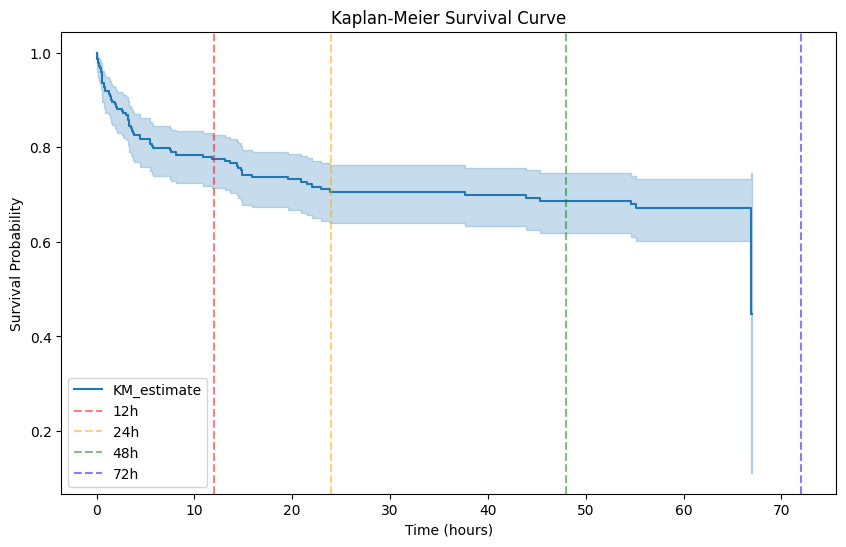

In [25]:
kmf = KaplanMeierFitter()
kmf.fit(durations=train['time_to_hit_hours'], event_observed=train['event'])

plt.figure(figsize=(10, 6))
kmf.plot_survival_function()
plt.title('Kaplan-Meier Survival Curve') # 전체 생존 곡선
plt.xlabel('Time (hours)')
plt.ylabel('Survival Probability') #생존확률 (대피구역에 아직 도달하지 않을 확률)
plt.axvline(x=12, color='red', linestyle='--', alpha=0.5, label='12h')
plt.axvline(x=24, color='orange', linestyle='--', alpha=0.5, label='24h')
plt.axvline(x=48, color='green', linestyle='--', alpha=0.5, label='48h')
plt.axvline(x=72, color='blue', linestyle='--', alpha=0.5, label='72h')
plt.legend()
plt.show()

0~12h 구간: 곡선이 가장 가파르게 떨어짐. 전체 이벤트의 상당수가 초반에 집중됨

12h 시점: 생존확률 약 0.78 → 22% 화재가 이미 도달

24h 시점: 생존확률 약 0.71 → 29% 화재 도달

48h 시점: 생존확률 약 0.69 → 31% 화재 

72h 이후: 곡선이 급격히 떨어지는데, 이건 마지막에 이벤트가 몰려있어서임


In [26]:
top_vars = [
    'dist_min_ci_0_5h',
    'alignment_abs',
    'log1p_growth'
]
for v in top_vars:
    print(f"\n===== {v} =====")
    print(train[v].describe())
    print(train[v].value_counts(dropna=False).head(10))


===== dist_min_ci_0_5h =====
count       221.000000
mean     124399.237725
std      171302.559054
min         306.954551
25%        2965.217571
50%       31758.581144
75%      200228.863652
max      757700.487102
Name: dist_min_ci_0_5h, dtype: float64
dist_min_ci_0_5h
6166.121596     1
2930.925956     1
3272.375090     1
64119.871377    1
18005.432261    1
35232.562968    1
3530.472886     1
8038.691359     1
31758.581144    1
1995.042356     1
Name: count, dtype: int64

===== alignment_abs =====
count    221.000000
mean       0.172704
std        0.329210
min        0.000000
25%        0.000000
50%        0.000000
75%        0.071697
max        0.999995
Name: alignment_abs, dtype: float64
alignment_abs
0.000000    160
0.054649      1
0.568898      1
0.882385      1
0.934634      1
0.106322      1
0.953682      1
0.437704      1
0.888017      1
0.373890      1
Name: count, dtype: int64

===== log1p_growth =====
count    221.000000
mean       0.389346
std        1.340348
min        0.00

In [27]:
# event=1인 화재들의 거리 분포 확인
hit_distances = train[train['event']==1]['dist_min_ci_0_5h']
print(f'event=1 최대 거리: {hit_distances.max()/1000:.1f}km')
print(f'event=1 평균 거리: {hit_distances.mean()/1000:.1f}km')
print(f'event=1 중앙값 거리: {hit_distances.median()/1000:.1f}km')
print(f'event=1 75th percentile: {hit_distances.quantile(0.75)/1000:.1f}km')

event=1 최대 거리: 4.7km
event=1 평균 거리: 2.3km
event=1 중앙값 거리: 2.4km
event=1 75th percentile: 2.8km


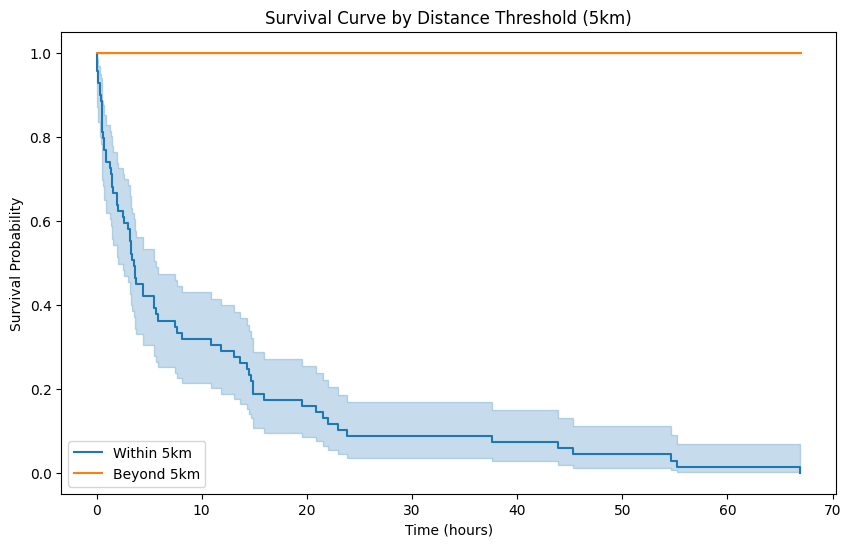

p-value: 1.49e-70


In [28]:
train['dist_group'] = (train['dist_min_ci_0_5h'] <= 5000).map({True: 'Within 5km', False: 'Beyond 5km'})

kmf_within = KaplanMeierFitter()
kmf_beyond = KaplanMeierFitter()

plt.figure(figsize=(10, 6))
kmf_within.fit(train[train['dist_group']=='Within 5km']['time_to_hit_hours'],
               train[train['dist_group']=='Within 5km']['event'], label='Within 5km')
kmf_within.plot_survival_function()

kmf_beyond.fit(train[train['dist_group']=='Beyond 5km']['time_to_hit_hours'],
               train[train['dist_group']=='Beyond 5km']['event'], label='Beyond 5km')
kmf_beyond.plot_survival_function()

plt.title('Survival Curve by Distance Threshold (5km)')
plt.xlabel('Time (hours)')
plt.ylabel('Survival Probability')
plt.show()

results_dist = logrank_test(
    train[train['dist_group']=='Within 5km']['time_to_hit_hours'],
    train[train['dist_group']=='Beyond 5km']['time_to_hit_hours'],
    event_observed_A=train[train['dist_group']=='Within 5km']['event'],
    event_observed_B=train[train['dist_group']=='Beyond 5km']['event']
)
print(f'p-value: {results_dist.p_value:.2e}')

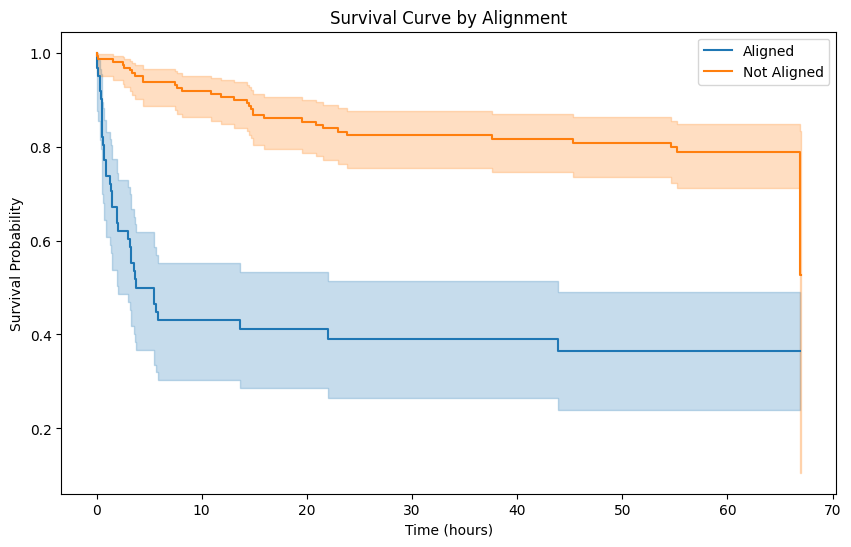

p-value: 1.29e-14


In [29]:
train['align_group'] = (train['alignment_abs'] > 0).map({True: 'Aligned', False: 'Not Aligned'})

kmf_aligned = KaplanMeierFitter()
kmf_not = KaplanMeierFitter()

plt.figure(figsize=(10, 6))
kmf_aligned.fit(train[train['align_group']=='Aligned']['time_to_hit_hours'],
                train[train['align_group']=='Aligned']['event'], label='Aligned')
kmf_aligned.plot_survival_function()

kmf_not.fit(train[train['align_group']=='Not Aligned']['time_to_hit_hours'],
            train[train['align_group']=='Not Aligned']['event'], label='Not Aligned')
kmf_not.plot_survival_function()

plt.title('Survival Curve by Alignment')
plt.xlabel('Time (hours)')
plt.ylabel('Survival Probability')
plt.show()

results_align = logrank_test(
    train[train['align_group']=='Aligned']['time_to_hit_hours'],
    train[train['align_group']=='Not Aligned']['time_to_hit_hours'],
    event_observed_A=train[train['align_group']=='Aligned']['event'],
    event_observed_B=train[train['align_group']=='Not Aligned']['event']
)
print(f'p-value: {results_align.p_value:.2e}')

dist_min (5km 기준)
아까랑 똑같이 Within 5km는 급격히 떨어지고 Beyond 5km는 1.0 유지. p-value 1.49e-70으로 압도적으로 significant(유의).
alignment_abs (0 vs 0 초과)
Aligned(파란선)가 Not Aligned(주황선)보다 생존확률이 훨씬 낮음. 즉 화재가 대피구역 방향으로 향하고 있으면 도달 확률이 높아짐. p-value 1.29e-14로 통계적으로 유의함.
두 그룹 신뢰구간이 겹치긴 하지만 dist_min과 달리 완벽하게 분리되지 않음. alignment_abs는 dist_min보다 예측력이 약하지만 보완적인 역할

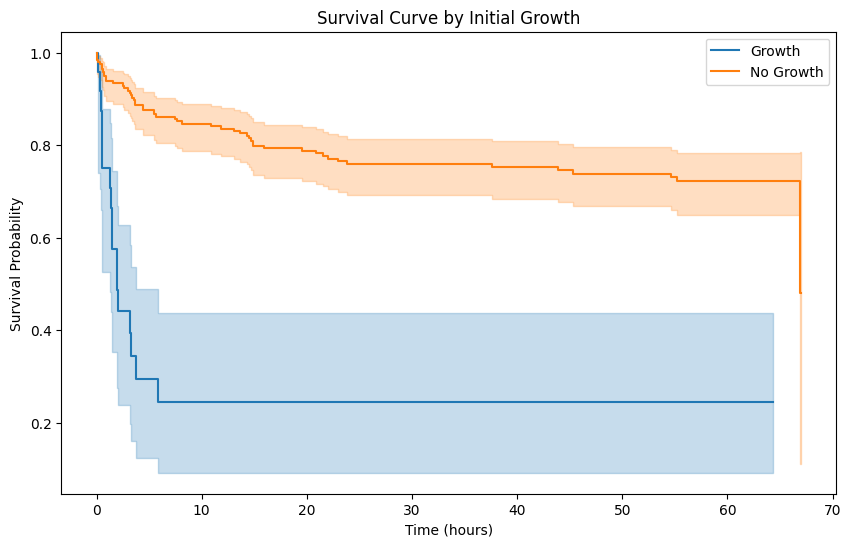

p-value: 2.38e-13
통계적으로 유의함


In [30]:
train['growth_group'] = (train['log1p_growth'] > 0).map({True: 'Growth', False: 'No Growth'})

kmf_growth = KaplanMeierFitter()
kmf_no = KaplanMeierFitter()

plt.figure(figsize=(10, 6))
kmf_growth.fit(train[train['growth_group']=='Growth']['time_to_hit_hours'],
               train[train['growth_group']=='Growth']['event'], label='Growth')
kmf_growth.plot_survival_function()

kmf_no.fit(train[train['growth_group']=='No Growth']['time_to_hit_hours'],
           train[train['growth_group']=='No Growth']['event'], label='No Growth')
kmf_no.plot_survival_function()

plt.title('Survival Curve by Initial Growth')
plt.xlabel('Time (hours)')
plt.ylabel('Survival Probability')
plt.show()

results_growth = logrank_test(
    train[train['growth_group']=='Growth']['time_to_hit_hours'],
    train[train['growth_group']=='No Growth']['time_to_hit_hours'],
    event_observed_A=train[train['growth_group']=='Growth']['event'],
    event_observed_B=train[train['growth_group']=='No Growth']['event']
)
print(f'p-value: {results_growth.p_value:.2e}')
print('통계적으로 유의함' if results_growth.p_value < 0.05 else '통계적으로 유의하지 않음')

Growth(파란선)는 초반 0~5시간에 급격히 떨어져서 약 0.25에서 평탄해짐. 초기에 면적이 성장한 화재는 빠르게 도달하는 경향있음.
No Growth(주황선)는 완만하게 떨어지며 72시간에도 0.7 수준 유지.
p-value 2.38e-13으로 통계적으로 유의

Growth 그룹이 24개밖에 없어서 신뢰구간이 매우 넓어 "샘플이 적어 불확실성이 크다"

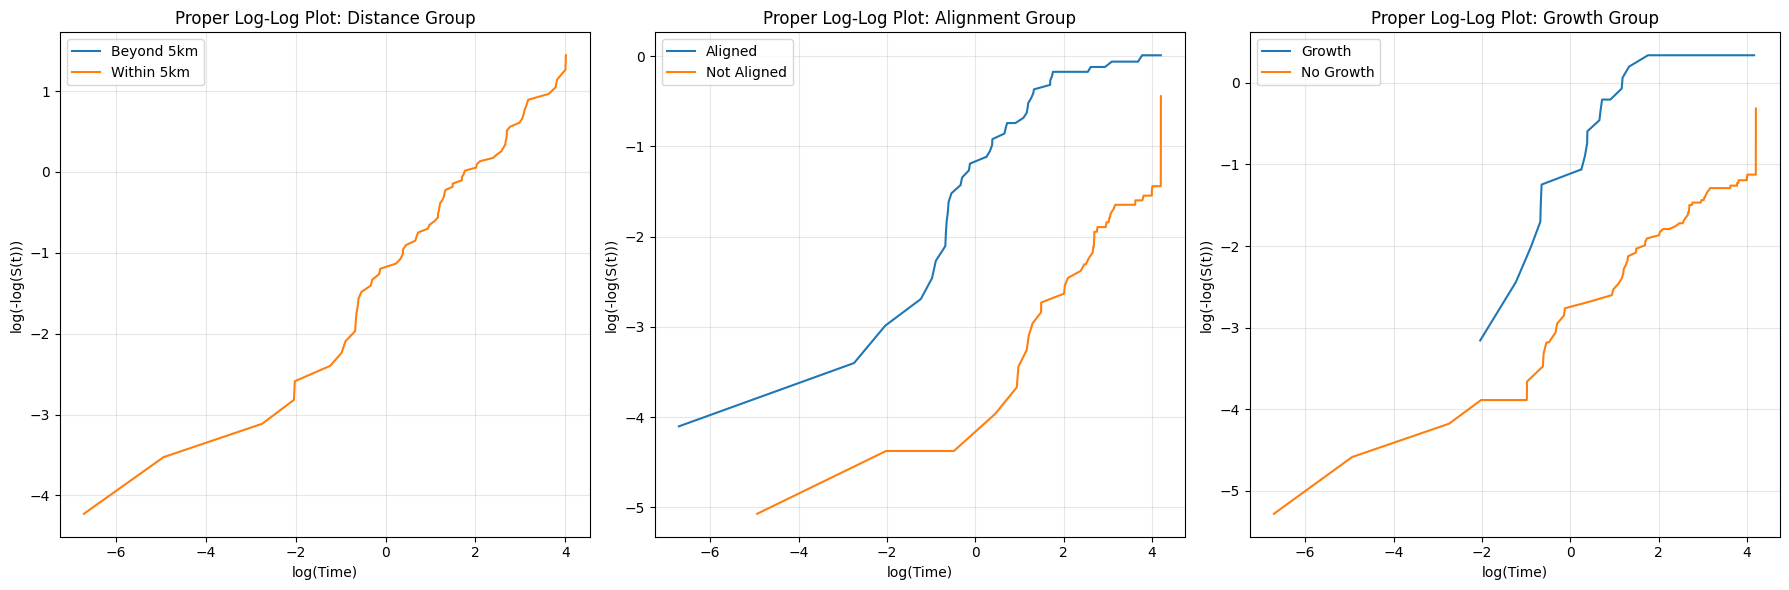

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

group_specs = [
    ('dist_group', 'Distance Group'),
    ('align_group', 'Alignment Group'),
    ('growth_group', 'Growth Group')
]

for ax, (group_col, title) in zip(axes, group_specs):
    for name, grouped_df in train.groupby(group_col):
        kmf = KaplanMeierFitter()
        kmf.fit(grouped_df['time_to_hit_hours'], grouped_df['event'], label=name)

        sf = kmf.survival_function_.copy()
        sf.columns = ['S']
        sf = sf.reset_index().rename(columns={'timeline': 'time'})

        # PH 점검용으로 유효 구간만 사용
        sf = sf[(sf['time'] > 0) & (sf['S'] > 0) & (sf['S'] < 1)].copy()

        sf['log_time'] = np.log(sf['time'])
        sf['loglogS'] = np.log(-np.log(sf['S']))

        ax.plot(sf['log_time'], sf['loglogS'], label=name)

    ax.set_title(f'Proper Log-Log Plot: {title}')
    ax.set_xlabel('log(Time)')
    ax.set_ylabel('log(-log(S(t)))')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

1. dist_min_ci_0_5h는 event와 매우 강하게 관련된 핵심 변수

다만 Cox 기준 hazard ratio가 과도하게 커짐, 계수가 불안정해짐, PH 가정을 “평행성”으로 판단하기가 사실상 불가능함

2. alignment_abs 세 개 중 Cox용 PH 가정에 가장 무난
   
정렬된 방향으로 퍼지는 화재가 더 빨리 위험구역에 접근한다 / 선이 심하게 교차하지 않고
위험 순서가 비교적 일관되며
전체적으로는 대체로 평행한 흐름을 유지한다 --> baseline Cox에 가장 넣기 좋은 후보

3. growth_group 초기 5시간 동안 확산이 실제로 진행된 화재일수록 이후 대피구역 접근 위험이 높다

   초반에는 growth의 효과가 매우 강하고
시간이 지나면 효과 크기가 상대적으로 줄어드는(기울기차이) --> Cox의 핵심 가정인 “시간이 지나도 hazard ratio가 일정하다”와는 약간 안 맞을 수 있음

Cox baseline 전 EDA 결론 

Kaplan-Meier 곡선과 log-log plot을 통해 거리, 진행 방향 정렬성, 초기 확산 여부가 모두 time-to-hit를 구분하는 데 유의한 변수임을 확인하였다. 다만 거리 변수는 5km 임계값 기준 이분화 시 그룹 간 사건 분포가 지나치게 극단적으로 분리되어 비례위험 가정 점검에는 한계가 있었다. 반면 alignment_abs는 위험 순서를 안정적으로 분리하면서도 log-log plot 상 큰 교차 없이 비교적 평행한 패턴을 보여 Cox 베이스라인에 가장 적합한 변수로 판단된다. growth_group은 의미 있는 분리력을 보였으나 시간에 따른 효과 변화 가능성이 관찰되어 해석에 주의가 필요하다.